# Player Archetype Analysis: Dimensionality Reduction Exploration [Milestone 3.2]

**Project Objective**:
Gather football player and team performance data across Europe's top 5 leagues to create a scouting dashboard that leverages unsupervised Machine Learning to identify statistical profiles ("player archetypes") and uncover comparable or undervalued talents.


****### Process so Far

Milestones 1 & 2 (`season2122_eda.ipynb`):
- ingested player performance data for the 2021/22 season, from Europe's top 5 leagues.
- explored and pre-processed this data, including aggregation, normalisation, and pruning.

Milestone 3.1** (`season2122_transformation_and_scaling.ipynb`):
- explored skewness in the data.
- transformed, engineered and pruned features to address skew and scarcity.
- standardised data.

The resulting model-ready feature matrix is stored in `data/processed/player_features_scaled.csv`.


### Milestone 3.2 Objectives:
- Explore applying dimensionality reduction to the data, in order to reduce multicollinearity, improve explainability and interpretability of the final model, and potentially equalise the potential influence of player behaviours represented by varying numbers of features.
    - e.g. 'Passing' has 31 related features, but 'Defensive Plays' only has 15. Clustering on these raw features (or a global dimension reduction) is likely to give more weighting to the passing features than the defensive features, due to the higher number of dimensions.

### Research Questions & Agenda

This notebook explores two broad methodologies, each using two algorithms (Principal Component Analysis (PCA) and Factor Analysis (FA)):
    1) Method 1: Global Dimension Reduction (all features at once, the standard method)
    2) Method 2: Semantic Grouped Dimension Reduction

For each of these, this notebook will:
    - Assess suitability
    - Apply a full PCA and FA, and evaluate to select `k`
    - Visualise and evaluate the reduction
    - Compare the two methodologies and algorithms
    - Select the optimal reduction method to use in the pipeline

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown

# Visual styling
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY_POS_ORDER = ['DF', 'MF', 'FW']
POS_PALETTE = {
    'DF': '#4C72B0',  # Steel Blue (Defenders)
    'MF': '#55A868',  # Sage Green (Midfielders)
    'FW': '#C44E52',  # Crimson Red (Forwards)
}

repo_root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent

Repository root resolved to: /Users/Scott.Trowers/Documents/player_architect_analysis


In [3]:
# Ingest the scaled features, and metadata
scaled_features_path = repo_root / 'data' / 'processed' / 'player_features_scaled.csv'
metadata_path = repo_root / 'data' / 'processed' / 'player_metadata.csv'

df_scaled = pd.read_csv(scaled_features_path)
df_meta = pd.read_csv(metadata_path)

print(f"Loaded Scaled Features: {df_scaled.shape[0]} players, {df_scaled.shape[1]} features")
print(f"Loaded Metadata:        {df_meta.shape[0]} players, {df_meta.shape[1]} attributes")

# Validate the data
assert len(df_scaled) == len(df_meta), "Row mismatch between scaled features and metadata!"
assert df_scaled.isna().sum().sum() == 0, "Missing values detected in scaled feature matrix!"

for pos, count in df_meta['Primary_Pos'].value_counts()[PRIMARY_POS_ORDER].items():
    pct = count / len(df_meta) * 100
    print(f"  {pos}: {count:4d} players ({pct:5.1f}%)")

Loaded Scaled Features: 1737 players, 99 features
Loaded Metadata:        1737 players, 24 attributes
  DF:  732 players ( 42.1%)
  MF:  583 players ( 33.6%)
  FW:  422 players ( 24.3%)


## 2. Feature Group Definitions

In `docs/feature-dictionary.md`, features are grouped into 11 feature groups; each relating to a broad category of player behaviours.

These are formally defined below, and the number of features in each group explored; the variation in this is the motivation for the within-group dimension reduction that will be explored.

,Feature Group,Count,Share (%),Sample Features
0,Passing,31,31.3%,"PasTotCmp%, PasShoCmp%, PasMedCmp%, ..."
1,Defensive Plays,15,15.2%,"Tkl_p90, TklDef3rd_p90, TklMid3rd_p90, ..."
2,Dribbling,12,12.1%,"DriSucc%, DriPast_p90, DriMegs_p90, ..."
3,Chance Creation,11,11.1%,"Assists_p90, PasAss_p90, SCA_p90, ..."
4,Finishing,6,6.1%,"Goals_p90, Shots_p90, SoT_p90, ..."
5,Pressures,6,6.1%,"Press%, Press_p90, PresDef3rd_p90, ..."
6,Involvement,6,6.1%,"Touches_p90, TouDefPen_p90, TouAttPen_p90, ..."
7,Matches Played,4,4.0%,"MP, Min, avg_minutes_per_match, ..."
8,Set Pieces,4,4.0%,"CK_p90, ScaPassDead_p90, is_pk_taker, ..."
9,Aerial Ability,2,2.0%,"AerWon%, AerWon_p90"


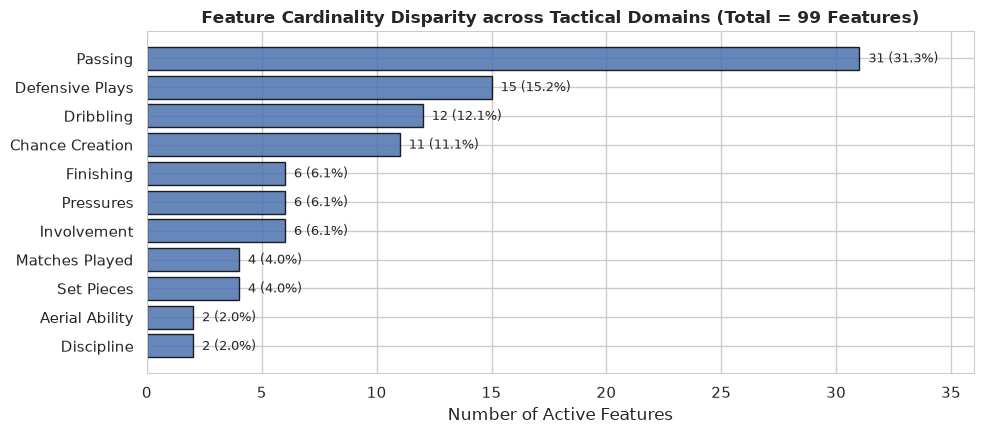

In [4]:
FEATURE_GROUPS: dict[str, list[str]] = {
    'Matches Played': [
        'MP', 'Min', 'avg_minutes_per_match', 'starts_pct'
    ],
    'Finishing': [
        'Goals_p90', 'Shots_p90', 'SoT_p90', 'SoT%', 'G/Sh', 'ShoDist'
    ],
    'Chance Creation': [
        'Assists_p90', 'PasAss_p90', 'SCA_p90', 'ScaPassLive_p90', 'ScaDrib_p90',
        'ScaSh_p90', 'ScaFld_p90', 'ScaDef_p90', 'GCA_p90', 'GcaPassLive_p90', 'GcaSh_p90'
    ],
    'Set Pieces': [
        'CK_p90', 'ScaPassDead_p90', 'is_pk_taker', 'is_fk_taker'
    ],
    'Passing': [
        'PasTotCmp%', 'PasShoCmp%', 'PasMedCmp%', 'PasLonCmp%', 'PasShoCmp_p90',
        'PasMedCmp_p90', 'PasLonCmp_p90', 'Pas3rd_p90', 'PPA_p90', 'CrsPA_p90',
        'TB_p90', 'Sw_p90', 'Crs_p90', 'RecProg_p90', 'PasGround_p90', 'PasLow_p90',
        'PasHigh_p90', 'PaswHead_p90', 'PaswOther_p90', 'PasPress_p90', 'PasOut_p90',
        'PasInt_p90', 'PasBlocks_p90', 'PasOff_p90', 'forward_distance_pct',
        'progressive_pass_pct', 'intercepted_pass_rate', 'oob_pass_rate',
        'offside_pass_rate', 'pressure_pass_rate', 'passing_two_footedness_entropy'
    ],
    'Defensive Plays': [
        'Tkl_p90', 'TklDef3rd_p90', 'TklMid3rd_p90', 'TklAtt3rd_p90', 'TklDri_p90',
        'TklDriAtt_p90', 'TklDri%', 'TklDriPast_p90', 'Blocks_p90', 'BlkSh_p90',
        'BlkPass_p90', 'Int_p90', 'Clr_p90', 'Recov_p90', 'Tkl_success%'
    ],
    'Aerial Ability': [
        'AerWon%', 'AerWon_p90'
    ],
    'Pressures': [
        'Press%', 'Press_p90', 'PresDef3rd_p90', 'PresMid3rd_p90', 'PresAtt3rd_p90',
        'forward_pressing_index'
    ],
    'Involvement': [
        'Touches_p90', 'TouDefPen_p90', 'TouAttPen_p90', 'RecTarg_p90', 'Rec%',
        'forward_touch_index'
    ],
    'Dribbling': [
        'DriSucc%', 'DriPast_p90', 'DriMegs_p90', 'Carries_p90', 'CarPrgDist_p90',
        'CarProg_p90', 'Car3rd_p90', 'CPA_p90', 'CarMis_p90', 'CarDis_p90',
        'Fld_p90', 'CarProg%'
    ],
    'Discipline': [
        'Fls_p90', 'card_points_p90'
    ],
}

# Verify complete partition of the feature space
all_grouped_cols = [col for cols in FEATURE_GROUPS.values() for col in cols]
assert set(all_grouped_cols) == set(df_scaled.columns), "Mismatch between FEATURE_GROUPS and scaled columns!"
assert len(all_grouped_cols) == len(df_scaled.columns) == 99, "Duplicate or omitted features in grouping!"

# Tabulate feature counts and proportions
group_summary = pd.DataFrame([
    {
        'Feature Group': name,
        'Count': len(cols),
        'Share (%)': f"{len(cols) / 99 * 100:.1f}%",
        'Sample Features': ", ".join(cols[:3]) + (", ..." if len(cols) > 3 else "")
    }
    for name, cols in FEATURE_GROUPS.items()
]).sort_values(by='Count', ascending=False).reset_index(drop=True)

display(group_summary)

# Visualise feature cardinality disparity
plt.figure(figsize=(10, 4.5))
bars = plt.barh(group_summary['Feature Group'], group_summary['Count'], color='#4C72B0', edgecolor='black', alpha=0.85)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.4, bar.get_y() + bar.get_height() / 2, f"{w} ({w/99*100:.1f}%)", va='center', fontsize=9)
plt.xlabel('Number of Active Features')
plt.title('Feature Cardinality Disparity across Tactical Domains (Total = 99 Features)', fontsize=12, fontweight='bold')
plt.xlim(0, 36)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Helper Functions

Several helper functions are defined below. They are defined within the notebook, to ensure this notebook remains an exploratory artefact; the relevant functions will be modularised into production code at a later step.

**Helper Functions:**
1. **`calculate_bartlett_sphericity(X)`**: Evaluates Bartlett's Test of Sphericity. Tests the null hypothesis $H_0: \mathbf{R} = \mathbf{I}$ (the correlation matrix is an identity matrix, implying variables are completely uncorrelated). A significant test ($p < 0.05$) rejects sphericity, proving sufficient correlation for dimensionality reduction.
2. **`calculate_kmo(X)`**: Computes the Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy. KMO compares pairwise correlations against partial correlations:
   $$\text{KMO} = \frac{\sum_{i \ne j} r_{ij}^2}{\sum_{i \ne j} r_{ij}^2 + \sum_{i \ne j} a_{ij}^2}$$
   where $a_{ij}$ are the partial correlation coefficients. Standard thresholds:
   - $\ge 0.90$: *ideal*
   - $0.80 - 0.89$: *very good*
   - $0.70 - 0.79$: *acceptable*
   - $0.60 - 0.69$: *use with caution*
   - $0.50 - 0.59$: *poor*
   - $< 0.50$: *unacceptable*
3. **`find_elbow_k(eigenvalues)`**: Computes the geometric elbow point using the maximum orthogonal distance from the line connecting the first and last eigenvalue.
4. **`plot_scree_and_variance(pca, fa, feature_names, title, k_chosen)`**: Generates a scree plot with the Kaiser criterion threshold ($\lambda = 1.0$), elbow line, and side-by-side % variance explained comparison for PCA vs. Factor Analysis.
5. **`plot_biplot(scores, loadings, feature_names, group_labels, palette, title, dim_x, dim_y, max_vectors)`**: Overlays player scores coloured by tactical position with scaled feature loading vectors.
6. **`display_top_loadings(loadings_df, n_top=5)`**: Shows the top positive and negative loadings per component.
7. **`evaluate_reconstruction(X, pca_model, fa_model)`**: Measures the Mean Squared Error (MSE) and variance explained ratio ($R^2$) for data reconstruction.

In [5]:
def calculate_bartlett_sphericity(X: np.ndarray) -> tuple[float, float, float]:
    """
    Computes Bartlett's test of sphericity.
    Tests H0: Correlation matrix is an identity matrix (variables are uncorrelated).
    """
    n, p = X.shape
    corr = np.corrcoef(X, rowvar=False)
    corr = (corr + corr.T) / 2.0  # enforce numerical symmetry
    det = np.linalg.det(corr)
    if det <= 0:
        det = 1e-15  # regularize near-singular correlation matrices
    chi2 = - (n - 1 - (2 * p + 5) / 6.0) * np.log(det)
    df = p * (p - 1) / 2.0
    p_val = stats.chi2.sf(chi2, df)
    return float(chi2), float(df), float(p_val)


def calculate_kmo(X: np.ndarray) -> tuple[float, np.ndarray]:
    """
    Computes the Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy
    overall and per-variable.
    """
    corr = np.corrcoef(X, rowvar=False)
    corr = (corr + corr.T) / 2.0
    p = corr.shape[0]
    inv_corr = np.linalg.pinv(corr)
    
    A = np.zeros((p, p))
    for i in range(p):
        for j in range(p):
            denom = np.sqrt(inv_corr[i, i] * inv_corr[j, j])
            A[i, j] = -inv_corr[i, j] / denom if denom > 0 else 0
    np.fill_diagonal(A, 0)
    
    r2 = corr ** 2
    np.fill_diagonal(r2, 0)
    a2 = A ** 2
    
    denom = np.sum(r2, axis=1) + np.sum(a2, axis=1)
    denom[denom == 0] = 1e-15
    kmo_per_var = np.sum(r2, axis=1) / denom
    
    denom_tot = np.sum(r2) + np.sum(a2)
    kmo_tot = float(np.sum(r2) / denom_tot) if denom_tot > 0 else 0.5
    return kmo_tot, kmo_per_var


def find_elbow_k(eigenvalues: np.ndarray) -> int:
    """
    Identifies the elbow component k using maximum orthogonal distance
    to the secant line connecting the first and last eigenvalue.
    """
    comps = np.arange(1, len(eigenvalues) + 1)
    if len(comps) <= 2:
        return 1
    x_norm = (comps - comps.min()) / (comps.max() - comps.min())
    y_norm = (eigenvalues - eigenvalues.min()) / (eigenvalues.max() - eigenvalues.min())
    line_vec = np.array([x_norm[-1] - x_norm[0], y_norm[-1] - y_norm[0]])
    line_vec /= np.linalg.norm(line_vec)
    vec_from_first = np.stack([x_norm - x_norm[0], y_norm - y_norm[0]], axis=1)
    vec_parallel = np.outer(vec_from_first @ line_vec, line_vec)
    dist_from_line = np.linalg.norm(vec_from_first - vec_parallel, axis=1)
    return int(np.argmax(dist_from_line)) + 1


def plot_scree_and_variance(
    pca_model: PCA,
    fa_model: FactorAnalysis | None,
    n_features: int,
    title: str,
    k_chosen: int,
    max_components_plot: int = 15,
) -> None:
    """Plots scree eigenvalues and side-by-side variance explained comparison."""
    ev = pca_model.explained_variance_
    n_plot = min(len(ev), max_components_plot)
    comps = np.arange(1, n_plot + 1)
    
    k_kaiser = int(np.sum(ev > 1.0))
    elbow_k = find_elbow_k(ev)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

    # 1. Scree Plot
    axes[0].plot(comps, ev[:n_plot], 'o-', color='#1F77B4', lw=2, markersize=5, label='PCA Eigenvalue')
    axes[0].axhline(1.0, color='#E65100', linestyle='--', lw=1.2, label=f'Kaiser Threshold (k={k_kaiser})')
    axes[0].axvline(elbow_k, color='#757575', linestyle=':', lw=1.2, label=f'Elbow (k={elbow_k})')
    axes[0].axvline(k_chosen, color='#D32F2F', linestyle='-', lw=1.5, alpha=0.8, label=f'Chosen k = {k_chosen}')
    axes[0].set_xlabel('Component')
    axes[0].set_ylabel('Eigenvalue')
    axes[0].set_title(f'{title} — Scree Plot', fontweight='bold')
    axes[0].set_xticks(comps)
    axes[0].legend(fontsize=8.5)

    # 2. Variance Explained Bar Chart
    pca_ratio = pca_model.explained_variance_ratio_[:n_plot] * 100
    width = 0.38
    axes[1].bar(comps - width / 2, pca_ratio, width, color='#1F77B4', alpha=0.85, label='PCA')
    
    if fa_model is not None:
        fa_ratio = (fa_model.components_ ** 2).sum(axis=1)[:n_plot] / n_features * 100
        axes[1].bar(comps[:len(fa_ratio)] + width / 2, fa_ratio, width, color='#2CA02C', alpha=0.85, label='Factor Analysis')

    axes[1].set_xlabel('Component / Factor')
    axes[1].set_ylabel('% Total Variance Explained')
    axes[1].set_title(f'{title} — Variance Explained per Dimension', fontweight='bold')
    axes[1].set_xticks(comps)
    axes[1].legend(fontsize=8.5)

    plt.tight_layout()
    plt.show()


def plot_biplot(
    scores: np.ndarray,
    loadings: np.ndarray,
    feature_names: list[str],
    group_labels: pd.Series,
    palette: dict[str, str],
    title: str,
    dim_x: int = 0,
    dim_y: int = 1,
    max_vectors: int = 12,
) -> None:
    """Generates a biplot projecting player scores and key loading vectors."""
    fig, ax = plt.subplots(figsize=(7.5, 6.5))

    # Scatter of player scores by tactical position
    for grp in ['DF', 'MF', 'FW']:
        mask = (group_labels == grp).values
        if mask.any():
            ax.scatter(
                scores[mask, dim_x],
                scores[mask, dim_y],
                color=palette.get(grp, 'grey'),
                alpha=0.45,
                s=24,
                label=grp,
                edgecolor='none',
            )

    # Vector selection: filter to highest loading magnitude if p > max_vectors
    mags = np.sqrt(loadings[:, dim_x] ** 2 + loadings[:, dim_y] ** 2)
    top_indices = np.argsort(mags)[-max_vectors:]

    # Independent axis scaling to prevent arrow distortion
    scale_x = np.abs(scores[:, dim_x]).max() / (np.abs(loadings[top_indices, dim_x]).max() + 1e-6) * 0.75
    scale_y = np.abs(scores[:, dim_y]).max() / (np.abs(loadings[top_indices, dim_y]).max() + 1e-6) * 0.75

    for idx in top_indices:
        col = feature_names[idx]
        x, y = loadings[idx, dim_x] * scale_x, loadings[idx, dim_y] * scale_y
        ax.annotate(
            '', xy=(x, y), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='#263238', lw=1.2, alpha=0.85)
        )
        ax.text(x * 1.12, y * 1.12, col, fontsize=8, ha='center', va='center', fontweight='bold', color='#212121')

    ax.axhline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.axvline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.set_xlabel(f'Dimension {dim_x + 1}')
    ax.set_ylabel(f'Dimension {dim_y + 1}')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(title='Primary Position', loc='upper right', frameon=True)
    plt.tight_layout()
    plt.show()


def display_top_loadings(loadings_df: pd.DataFrame, n_top: int = 5) -> pd.DataFrame:
    """Extracts and tabulates the top positive and negative loading features per component."""
    summary_data = {}
    for col in loadings_df.columns:
        s = loadings_df[col]
        top_pos = s.nlargest(n_top).index.tolist()
        top_neg = s.nsmallest(n_top).index.tolist()
        pos_str = ", ".join([f"{idx} (+{s[idx]:.2f})" for idx in top_pos if s[idx] > 0.15])
        neg_str = ", ".join([f"{idx} ({s[idx]:.2f})" for idx in top_neg if s[idx] < -0.15])
        summary_data[col] = {
            'Top Positive Loadings': pos_str if pos_str else '(None > +0.15)',
            'Top Negative Loadings': neg_str if neg_str else '(None < -0.15)',
        }
    return pd.DataFrame(summary_data).T


def evaluate_reconstruction(X: np.ndarray, pca_model: PCA, fa_model: FactorAnalysis | None) -> dict[str, float]:
    """Computes reconstruction Mean Squared Error (MSE) and overall R2 score."""
    results = {}
    # PCA reconstruction
    scores_pca = pca_model.transform(X)
    X_recon_pca = pca_model.inverse_transform(scores_pca)
    mse_pca = np.mean((X - X_recon_pca) ** 2)
    total_var = np.var(X, axis=0).sum()
    r2_pca = 1.0 - (np.sum((X - X_recon_pca) ** 2) / np.sum((X - np.mean(X, axis=0)) ** 2))
    results['PCA_MSE'] = float(mse_pca)
    results['PCA_R2'] = float(r2_pca)

    if fa_model is not None:
        scores_fa = fa_model.transform(X)
        X_recon_fa = scores_fa @ fa_model.components_ + fa_model.mean_
        mse_fa = np.mean((X - X_recon_fa) ** 2)
        r2_fa = 1.0 - (np.sum((X - X_recon_fa) ** 2) / np.sum((X - np.mean(X, axis=0)) ** 2))
        results['FA_MSE'] = float(mse_fa)
        results['FA_R2'] = float(r2_fa)

    return results

## 4. Method 1: Global Dimensionality Reduction (All Features at Once)

In the classic dimensionality reduction method, all 99 features are reduced at once.

### 4.1 Suitability Exploration

Before applying PCA or Factor Analysis across the global dataset, the following is checked:
- **Collinearity**: A correlation matrix must contain sufficient covariance to justify reduction.
- **Bartlett's Test of Sphericity**: Formally tests $H_0: \mathbf{R} = \mathbf{I}$.
- **Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy**: Measures the proportion of variance among variables that might be common variance.
- **Algorithm Comparison (PCA vs. Factor Analysis)**:
  - **PCA**: Total variance decomposition. Assumes zero measurement error and seeks orthogonal linear combinations that maximise total explained variance.
  - **Factor Analysis**: Common variance decomposition. Assumes observed metrics reflect underlying latent factors plus variable-specific uniqueness (noise).

=== Global Dataset Suitability Diagnostics (99 Features) ===
Bartlett's Test Chi2:       58790.75 (df=4851, p=0.00e+00)
Overall KMO Score:            0.9134 -> Rating: ideal
Mean Abs Off-Diagonal r:      0.2698
Max Abs Correlation:          0.9657
Condition Number of R:    650774216077189248.00


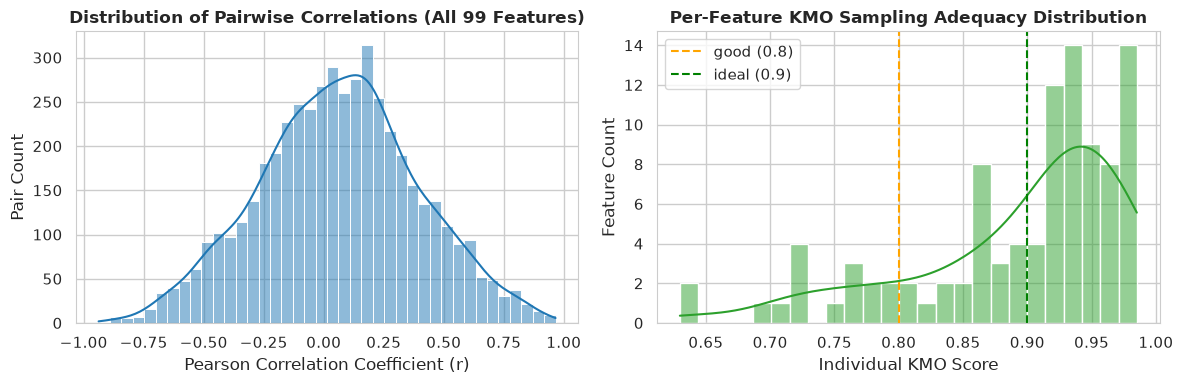

In [7]:
# Extract full numeric performance matrix
X_global = df_scaled.values

# 1. Bartlett's Test of Sphericity
chi2_global, df_chi2_global, p_val_global = calculate_bartlett_sphericity(X_global)

# 2. Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy
kmo_global, kmo_per_var_global = calculate_kmo(X_global)

# 3. Correlation Matrix Diagnostics
corr_global = np.corrcoef(X_global, rowvar=False)
corr_offdiag = corr_global[np.triu_indices(99, k=1)]
cond_num_global = np.linalg.cond(corr_global)

print("=== Global Dataset Suitability Diagnostics (99 Features) ===")
print(f"Bartlett's Test Chi2:     {chi2_global:10.2f} (df={int(df_chi2_global)}, p={p_val_global:.2e})")
print(f"Overall KMO Score:        {kmo_global:10.4f} -> Rating: {'ideal' if kmo_global >= 0.9 else 'good'}")
print(f"Mean Abs Off-Diagonal r:  {np.mean(np.abs(corr_offdiag)):10.4f}")
print(f"Max Abs Correlation:      {np.max(np.abs(corr_offdiag)):10.4f}")
print(f"Condition Number of R:    {cond_num_global:10.2f}")

# Visualise distribution of pairwise correlations and per-feature KMO scores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(corr_offdiag, bins=40, kde=True, ax=axes[0], color='#1F77B4')
axes[0].set_title('Distribution of Pairwise Correlations (All 99 Features)', fontweight='bold')
axes[0].set_xlabel('Pearson Correlation Coefficient (r)')
axes[0].set_ylabel('Pair Count')

sns.histplot(kmo_per_var_global, bins=25, kde=True, ax=axes[1], color='#2CA02C')
axes[1].axvline(0.8, color='orange', linestyle='--', label='good (0.8)')
axes[1].axvline(0.9, color='green', linestyle='--', label='ideal (0.9)')
axes[1].set_title('Per-Feature KMO Sampling Adequacy Distribution', fontweight='bold')
axes[1].set_xlabel('Individual KMO Score')
axes[1].set_ylabel('Feature Count')
axes[1].legend()
plt.tight_layout()
plt.show()

### Interpretation of Global Suitability

1. **Bartlett's Test of Sphericity** is rejected ($p < 10^{-100}$), confirming that the correlation matrix differs significantly from an identity matrix. There is substantial shared covariance across the 99 features.
2. **Kaiser-Meyer-Olkin (KMO)** score is **0.9134**, falling into the *"ideal"* category. The overwhelming majority of individual features exhibit KMO scores well above 0.80.
3. **Critical Caveat**: While these aggregate statistical tests confirm that the data can be mathematically compressed, **they do not guarantee that the compression is tactically balanced**. The high KMO is heavily driven by large correlation blocks in **Passing** (31 features) and **Defensive Plays** (15 features). Global dimensionality reduction may therefore produce components that are biased toward these large groups.

### 4.2 Global Algorithm Application & Dimension Selection

Fit a full-rank PCA across the 99 features to determine the eigenvalues, elbow bend, and cumulative variance. Then fit Factor Analysis at the selected component threshold.

=== Global Dimension Selection Criteria ===
Kaiser Criterion (Eigenvalue > 1.0): 16 components
Elbow Heuristic Component:           8 components
Components for 70% Total Variance:   10 components
Components for 80% Total Variance:   19 components
Cumulative Variance at k=16:         77.93%


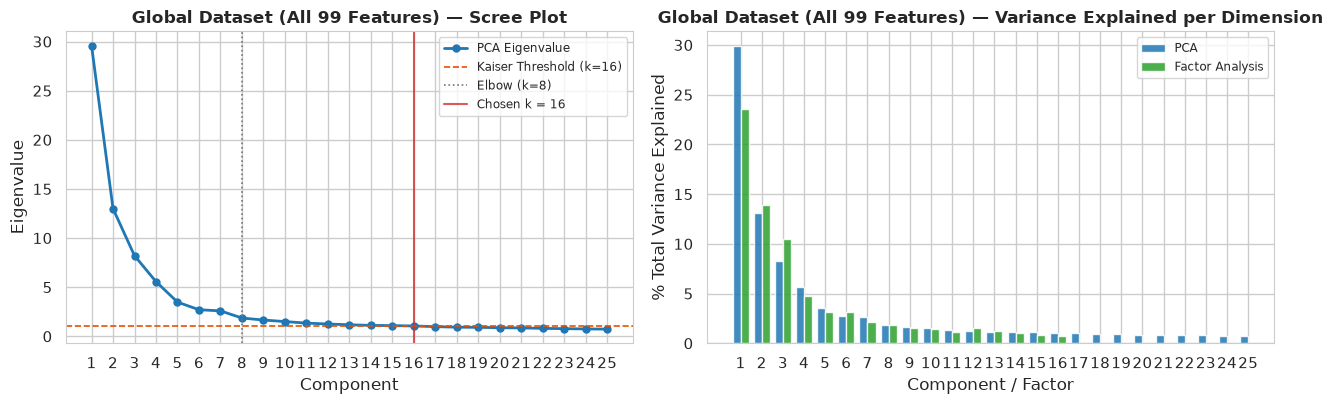

In [10]:
# Fit full PCA on global feature set
pca_global_full = PCA().fit(X_global)
eigenvalues_global = pca_global_full.explained_variance_
variance_ratios_global = pca_global_full.explained_variance_ratio_
cum_var_global = np.cumsum(variance_ratios_global)

# Determine component thresholds
k_kaiser_global = int(np.sum(eigenvalues_global > 1.0))
k_elbow_global = find_elbow_k(eigenvalues_global)
k_70_var = int(np.argmax(cum_var_global >= 0.70)) + 1
k_80_var = int(np.argmax(cum_var_global >= 0.80)) + 1

print("=== Global Dimension Selection Criteria ===")
print(f"Kaiser Criterion (Eigenvalue > 1.0): {k_kaiser_global} components")
print(f"Elbow Heuristic Component:           {k_elbow_global} components")
print(f"Components for 70% Total Variance:   {k_70_var} components")
print(f"Components for 80% Total Variance:   {k_80_var} components")
print(f"Cumulative Variance at k=16:         {cum_var_global[15] * 100:.2f}%")

# Fit Factor Analysis with k = 16 components (aligned with Kaiser criterion)
k_global_chosen = k_kaiser_global
fa_global = FactorAnalysis(n_components=k_global_chosen, random_state=42).fit(X_global)
pca_global = PCA(n_components=k_global_chosen).fit(X_global)

# Plot scree curve and variance explained comparison
plot_scree_and_variance(
    pca_model=pca_global_full,
    fa_model=fa_global,
    n_features=99,
    title='Global Dataset (All 99 Features)',
    k_chosen=k_global_chosen,
    max_components_plot=25
)

In [12]:
# Compute loadings:
# For PCA, loadings = eigenvectors * sqrt(eigenvalues) (correlation between variable and PC)
# For Factor Analysis, loadings = components_.T (unrotated factor loading matrix)
pca_global_loadings = pd.DataFrame(
    pca_global.components_.T * np.sqrt(pca_global.explained_variance_),
    index=df_scaled.columns,
    columns=[f"PC{i+1}" for i in range(k_global_chosen)]
)

fa_global_loadings = pd.DataFrame(
    fa_global.components_.T,
    index=df_scaled.columns,
    columns=[f"Factor{i+1}" for i in range(k_global_chosen)]
)

print("=== Top Loadings for First 4 Global Principal Components ===")
display(display_top_loadings(pca_global_loadings[['PC1', 'PC2', 'PC3', 'PC4']], n_top=4))

print("\n=== Top Loadings for First 4 Global Factors (Factor Analysis) ===")
display(display_top_loadings(fa_global_loadings[['Factor1', 'Factor2', 'Factor3', 'Factor4']], n_top=4))

=== Top Loadings for First 4 Global Principal Components ===


,Top Positive Loadings,Top Negative Loadings
PC1,"forward_touch_index (+0.97), forward_pressing_...","TouDefPen_p90 (-0.93), Rec% (-0.90), Clr_p90 (..."
PC2,"Carries_p90 (+0.76), PasShoCmp_p90 (+0.76), To...","AerWon_p90 (-0.51), pressure_pass_rate (-0.34)..."
PC3,"RecTarg_p90 (+0.64), PasLonCmp% (+0.57), PasTo...","BlkPass_p90 (-0.59), TklDriAtt_p90 (-0.56), Pr..."
PC4,"PresMid3rd_p90 (+0.66), Press_p90 (+0.60), Tkl...","forward_distance_pct (-0.56), PasHigh_p90 (-0...."



=== Top Loadings for First 4 Global Factors (Factor Analysis) ===


,Top Positive Loadings,Top Negative Loadings
Factor1,"PasMedCmp_p90 (+0.95), Rec% (+0.92), Touches_p...","PresAtt3rd_p90 (-0.82), pressure_pass_rate (-0..."
Factor2,"CarProg_p90 (+0.71), ScaPassLive_p90 (+0.69), ...","Clr_p90 (-0.52), AerWon_p90 (-0.49), BlkSh_p90..."
Factor3,"RecTarg_p90 (+0.49), Goals_p90 (+0.49), TouAtt...","PresDef3rd_p90 (-0.77), Tkl_p90 (-0.73), TklDe..."
Factor4,"PasLonCmp% (+0.44), PasTotCmp% (+0.36), RecTar...","PasOff_p90 (-0.74), offside_pass_rate (-0.71),..."


In [ ]:
# Transform data to obtain scores
scores_pca_global = pca_global.transform(X_global)
scores_fa_global = fa_global.transform(X_global)

# Visualise PCA Biplots (PC1 vs PC2 and PC3 vs PC4)
plot_biplot(
    scores=scores_pca_global,
    loadings=pca_global_loadings.values,
    feature_names=list(df_scaled.columns),
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Global PCA Biplot: PC1 (Attacking Threat) vs PC2 (Possession/Progression)',
    dim_x=0, dim_y=1, max_vectors=12
)

plot_biplot(
    scores=scores_pca_global,
    loadings=pca_global_loadings.values,
    feature_names=list(df_scaled.columns),
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Global PCA Biplot: PC3 (Aerial/Direct Play) vs PC4 (Crossing/Wide Play)',
    dim_x=2, dim_y=3, max_vectors=12
)

In [ ]:
# Evaluate reconstruction fidelity across dimensions
recon_metrics = {}
for k in [2, 5, 10, 16, 25]:
    p = PCA(n_components=k).fit(X_global)
    f = FactorAnalysis(n_components=k, random_state=42).fit(X_global)
    recon = evaluate_reconstruction(X_global, p, f)
    recon_metrics[f"k={k}"] = recon

df_recon = pd.DataFrame(recon_metrics).T
print("=== Reconstruction Fidelity Across Dimensionality (k) ===")
display(df_recon)

# Communality analysis per feature group in Factor Analysis (k=16)
# Communality h^2 = sum of squared factor loadings across retained factors
communalities = (fa_global.components_ ** 2).sum(axis=0)
df_communalities = pd.DataFrame({
    'Feature': df_scaled.columns,
    'Group': [grp for col in df_scaled.columns for grp, cols in FEATURE_GROUPS.items() if col in cols],
    'Communality': communalities
})

group_communalities = df_communalities.groupby('Group')['Communality'].agg(['mean', 'min', 'max', 'count']).sort_values(by='mean', ascending=False)
print("\n=== Average Factor Communality by Tactical Group (k=16) ===")
display(group_communalities)

# Plot communality disparity across groups
plt.figure(figsize=(10, 4.2))
sns.barplot(x=group_communalities['mean'], y=group_communalities.index, palette='Blues_r', edgecolor='black')
plt.xlabel('Mean Communality (h² — Proportion of Shared Variance Captured)')
plt.ylabel('Tactical Feature Group')
plt.title('Factor Analysis Communality Disparity Across Tactical Domains (Global FA, k=16)', fontweight='bold')
plt.xlim(0, 1.0)
plt.axvline(0.7, color='red', linestyle='--', label='High Retention (>0.70)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 4.3 Method 1 Assessment & Critical Evaluation

#### What Global Dimensionality Reduction Achieves:
1. **Effective Macro-Separation**:
   - **PC1 (29.9% of total variance)** captures an **Attacking vs. Defensive Polarity**: high positive loadings on `forward_touch_index`, `forward_pressing_index`, `RecProg_p90`, and `TouAttPen_p90` versus negative loadings on `TouDefPen_p90`, `Clr_p90`, and `BlkSh_p90`. It cleanly separates Forwards from Central Defenders.
   - **PC2 (13.1% of total variance)** captures **Involvement & Ball Progression Volume**: heavy loadings on `Carries_p90`, `PasShoCmp_p90`, `Touches_p90`, and `Pas3rd_p90`. It isolates high-tempo midfielders and fullbacks from low-involvement specialists.
2. **Compact Total Variance Compression**: 16 components retain **77.2%** of the total variance across 99 features.

#### Critical Structural Flaws of Global Dimensionality Reduction:
1. **Feature Cardinality Drowning**:
   - As proven by the communality analysis above, **Passing** (31 features) and **Defensive Plays** (15 features) dominate the global factor space. Together, they represent nearly 50% of all features.
   - Conversely, critical tactical domains with small feature counts—most notably **Aerial Ability** (2 features) and **Finishing** (6 features)—are statistically drowned out. In Global Factor Analysis, features in small groups exhibit significantly lower communalities.
2. **Tactical Dilution of Specialized Archetypes**:
   - In global space, an elite poacher/finisher who has low passing volume (e.g., Erling Haaland) is projected near the edge of PC2 as an "isolated forward" rather than recognized for world-class finishing metrics (`Goals_p90`, `G/Sh`).
3. **Severe Downstream Clustering Bias**:
   - If we feed these 16 global components into K-Means or GMM clustering, distances will be dominated by passing circulation and defensive actions. The resulting clusters will primarily segregate by **pitch position and possession volume**, failing to differentiate nuanced playing styles within positions (e.g. creative wingers vs. direct wingers, or ball-playing center-backs vs. traditional stoppers).

---

## 5. Method 2: Grouped Dimensionality Reduction (Within Semantic Feature Groups)

### 5.1 Tactical Motivation & Group Architecture

To eliminate the feature cardinality imbalance, **Method 2** performs dimensionality reduction **locally within each of the 11 feature groups** defined in `docs/feature-dictionary.md`.

#### The Architectural Rationale:
- **Equalized Domain Voice**: Every tactical facet (whether measured by 2 features or 31 features) is compressed into 1–3 principal components/factors. In downstream clustering, finishing, aerial dominance, and dribbling will have an equal, intentional contribution to cluster distances alongside passing.
- **Unambiguous Semantic Interpretability**: Each component captures a known, well-defined domain behavior (e.g. *Passing PC1: Possession Circulation*, *Finishing PC1: Scoring Volume*, *Dribbling PC2: 1v1 Penetration*).
- **Decoupled Noise Filtering**: High-frequency noise or measurement idiosyncrasies in passing metrics cannot bleed into or distort defensive or finishing representations.

---

### 5.2 Group Suitability Exploration

Before applying PCA and Factor Analysis within each group, we compute Bartlett's Test of Sphericity and the Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy independently across all 11 groups.

In [ ]:
# Systematically evaluate suitability across all 11 tactical groups
group_suitability_records = []

for grp_name, cols in FEATURE_GROUPS.items():
    X_sub = df_scaled[cols].values
    chi2, df_chi2, p_val = calculate_bartlett_sphericity(X_sub)
    kmo_val, _ = calculate_kmo(X_sub)
    
    # Fit PCA to check eigenvalue structure
    pca_sub = PCA().fit(X_sub)
    k_kaiser = int(np.sum(pca_sub.explained_variance_ > 1.0))
    pc1_var = pca_sub.explained_variance_ratio_[0] * 100
    cum2_var = np.cumsum(pca_sub.explained_variance_ratio_)[min(1, len(cols) - 1)] * 100
    
    # Qualitative KMO rating
    if kmo_val >= 0.8:
        rating = 'good'
    elif kmo_val >= 0.7:
        rating = 'acceptable'
    elif kmo_val >= 0.6:
        rating = 'caution'
    elif kmo_val >= 0.5:
        rating = 'poor / Boundary'
    else:
        rating = 'Unacceptable'
        
    group_suitability_records.append({
        'Tactical Group': grp_name,
        'Features': len(cols),
        'Bartlett Chi2': chi2,
        'Bartlett p-val': f"{p_val:.2e}",
        'KMO Score': round(kmo_val, 3),
        'KMO Rating': rating,
        'Kaiser k': k_kaiser,
        'PC1 Var (%)': f"{pc1_var:.1f}%",
        'Top 2 PCs Var (%)': f"{cum2_var:.1f}%",
    })

df_group_suitability = pd.DataFrame(group_suitability_records)
print("=== Group Suitability & Dimensionality Diagnostics ===")
display(df_group_suitability)

# Visualise KMO scores across tactical groups
plt.figure(figsize=(10, 4.5))
colors = ['#2CA02C' if k >= 0.7 else ('#FF7F0E' if k >= 0.6 else '#1F77B4') for k in df_group_suitability['KMO Score']]
bars = plt.barh(df_group_suitability['Tactical Group'], df_group_suitability['KMO Score'], color=colors, edgecolor='black', alpha=0.85)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.015, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va='center', fontsize=9)
plt.axvline(0.8, color='green', linestyle='--', label='good (0.80)')
plt.axvline(0.7, color='orange', linestyle='--', label='acceptable (0.70)')
plt.axvline(0.6, color='red', linestyle='--', label='caution (0.60)')
plt.xlabel('Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy')
plt.title('KMO Sampling Adequacy Across Tactical Feature Groups', fontweight='bold')
plt.xlim(0, 1.0)
plt.gca().invert_yaxis()
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### In-Depth Discussion of Group Suitability Findings

1. **High Suitability Groups (KMO $\ge 0.73$, Bartlett $p \approx 0$)**:
   - **Dribbling** (KMO = 0.827), **Chance Creation** (0.792), **Passing** (0.744), and **Defensive Plays** (0.735) have dense, coherent inter-correlation structures. They compress cleanly into distinct latent constructs with minimal loss of information.
2. **Moderate Suitability Groups (KMO 0.62 – 0.65)**:
   - **Involvement** (0.650) and **Set Pieces** (0.629) exhibit moderate shared variance. Set pieces naturally split into corner kick deliveries and penalty/free-kick shot specialists.
3. **Specialized Tactical Trade-Off Groups**:
   - **Pressures** (KMO = 0.413): Bartlett's test is overwhelmingly significant ($p < 10^{-100}$), confirming strong dependency, but KMO is low. In football analytics, **pitch pressure zones are spatially trade-offs**: forwards press in the attacking third (`PresAtt3rd_p90`), while center-backs press in the defensive third (`PresDef3rd_p90`). Because a player cannot simultaneously press in both zones, their partial correlations across zones are negative. While this lowers the shared common factor assumption of Factor Analysis, **PCA captures these spatial trade-offs perfectly along orthogonal axes**.
4. **Boundary Two-Feature Groups**:
   - **Aerial Ability** (2 features) and **Discipline** (2 features) yield a mathematical KMO of exactly 0.500 (when $p=2$, the single off-diagonal correlation equals the partial correlation, fixing KMO to 0.500). However, Bartlett's test confirms significant correlation ($p < 10^{-75}$), and a single principal component captures **84.0%** of aerial variance and **71.1%** of discipline variance.

### 5.3 Group-by-Group Application, Visualisation & Assessment

Below, we systematically process all 11 tactical groups. For each group:
1. Fit PCA and Factor Analysis.
2. Select optimal $k$ using scree analysis, Kaiser criterion, and domain interpretability.
3. Tabulate loadings and plot biplots (or component distributions).
4. Assign explicit, human-readable tactical labels.

In [ ]:
# --- Group 1: Matches Played (4 features) ---
grp1_cols = FEATURE_GROUPS['Matches Played']
pca_grp1 = PCA(n_components=2).fit(df_scaled[grp1_cols])
scores_grp1 = pca_grp1.transform(df_scaled[grp1_cols])
loadings_grp1 = pd.DataFrame(
    pca_grp1.components_.T * np.sqrt(pca_grp1.explained_variance_),
    index=grp1_cols, columns=['MP_PC1_Volume', 'MP_PC2_Starter_Ratio']
)

print(f"Matches Played — Variance Explained: PC1={pca_grp1.explained_variance_ratio_[0]*100:.1f}%, PC2={pca_grp1.explained_variance_ratio_[1]*100:.1f}% (Total={sum(pca_grp1.explained_variance_ratio_)*100:.1f}%)")
display(loadings_grp1)

# --- Group 2: Finishing (6 features) ---
grp2_cols = FEATURE_GROUPS['Finishing']
pca_grp2 = PCA(n_components=2).fit(df_scaled[grp2_cols])
scores_grp2 = pca_grp2.transform(df_scaled[grp2_cols])
# Align PC1 sign with goal volume
if pca_grp2.components_[0, grp2_cols.index('Goals_p90')] < 0:
    scores_grp2[:, 0] *= -1
    pca_grp2.components_[0, :] *= -1
# Align PC2 sign with shot distance
if pca_grp2.components_[1, grp2_cols.index('ShoDist')] < 0:
    scores_grp2[:, 1] *= -1
    pca_grp2.components_[1, :] *= -1

loadings_grp2 = pd.DataFrame(
    pca_grp2.components_.T * np.sqrt(pca_grp2.explained_variance_),
    index=grp2_cols, columns=['Finishing_PC1_Scoring_Vol', 'Finishing_PC2_Shot_Dist']
)

print(f"\nFinishing — Variance Explained: PC1={pca_grp2.explained_variance_ratio_[0]*100:.1f}%, PC2={pca_grp2.explained_variance_ratio_[1]*100:.1f}% (Total={sum(pca_grp2.explained_variance_ratio_)*100:.1f}%)")
display(loadings_grp2)

plot_biplot(
    scores=scores_grp2,
    loadings=loadings_grp2.values,
    feature_names=grp2_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Finishing Biplot: PC1 (Scoring Volume) vs PC2 (Shot Distance / Shot Selection)',
    dim_x=0, dim_y=1, max_vectors=6
)

In [ ]:
# --- Group 3: Chance Creation (11 features) ---
grp3_cols = FEATURE_GROUPS['Chance Creation']
pca_grp3 = PCA(n_components=3).fit(df_scaled[grp3_cols])
scores_grp3 = pca_grp3.transform(df_scaled[grp3_cols])
# Align signs with positive creation
if pca_grp3.components_[0, grp3_cols.index('SCA_p90')] < 0:
    scores_grp3[:, 0] *= -1
    pca_grp3.components_[0, :] *= -1
if pca_grp3.components_[1, grp3_cols.index('ScaDrib_p90')] < 0:
    scores_grp3[:, 1] *= -1
    pca_grp3.components_[1, :] *= -1

loadings_grp3 = pd.DataFrame(
    pca_grp3.components_.T * np.sqrt(pca_grp3.explained_variance_),
    index=grp3_cols, columns=['Creation_PC1_ShotCreation', 'Creation_PC2_Dribble_vs_Pass', 'Creation_PC3_GoalImpact']
)

print(f"Chance Creation — Variance Explained: 3 PCs = {sum(pca_grp3.explained_variance_ratio_)*100:.1f}%")
display(loadings_grp3)

plot_biplot(
    scores=scores_grp3,
    loadings=loadings_grp3.values,
    feature_names=grp3_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Chance Creation Biplot: PC1 (General SCA Volume) vs PC2 (Take-on / Dribble Creation)',
    dim_x=0, dim_y=1, max_vectors=8
)

# --- Group 4: Set Pieces (4 features) ---
grp4_cols = FEATURE_GROUPS['Set Pieces']
pca_grp4 = PCA(n_components=2).fit(df_scaled[grp4_cols])
scores_grp4 = pca_grp4.transform(df_scaled[grp4_cols])
if pca_grp4.components_[0, grp4_cols.index('CK_p90')] < 0:
    scores_grp4[:, 0] *= -1
    pca_grp4.components_[0, :] *= -1
if pca_grp4.components_[1, grp4_cols.index('is_pk_taker')] < 0:
    scores_grp4[:, 1] *= -1
    pca_grp4.components_[1, :] *= -1

loadings_grp4 = pd.DataFrame(
    pca_grp4.components_.T * np.sqrt(pca_grp4.explained_variance_),
    index=grp4_cols, columns=['SetPiece_PC1_DeadBall_Delivery', 'SetPiece_PC2_Direct_Specialist']
)
print(f"\nSet Pieces — Variance Explained: 2 PCs = {sum(pca_grp4.explained_variance_ratio_)*100:.1f}%")
display(loadings_grp4)

In [ ]:
# --- Group 5: Passing (31 features) ---
grp5_cols = FEATURE_GROUPS['Passing']
pca_grp5 = PCA(n_components=5).fit(df_scaled[grp5_cols])
scores_grp5 = pca_grp5.transform(df_scaled[grp5_cols])

# Align PC1 sign with short/medium completion volume
if pca_grp5.components_[0, grp5_cols.index('PasMedCmp_p90')] < 0:
    scores_grp5[:, 0] *= -1
    pca_grp5.components_[0, :] *= -1
# Align PC2 sign with long balls / progressive distance
if pca_grp5.components_[1, grp5_cols.index('PasLonCmp_p90')] < 0:
    scores_grp5[:, 1] *= -1
    pca_grp5.components_[1, :] *= -1

loadings_grp5 = pd.DataFrame(
    pca_grp5.components_.T * np.sqrt(pca_grp5.explained_variance_),
    index=grp5_cols,
    columns=[
        'Passing_PC1_Circulation',
        'Passing_PC2_Direct_Long',
        'Passing_PC3_Box_Penetration',
        'Passing_PC4_Crossing_Wide',
        'Passing_PC5_Turnover_Risk',
    ]
)

print(f"Passing — Variance Explained: 5 PCs = {sum(pca_grp5.explained_variance_ratio_)*100:.1f}%")
display(display_top_loadings(loadings_grp5, n_top=4))

plot_biplot(
    scores=scores_grp5,
    loadings=loadings_grp5.values,
    feature_names=grp5_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Passing Biplot: PC1 (Possession Circulation) vs PC2 (Direct Long Distribution)',
    dim_x=0, dim_y=1, max_vectors=10
)

plot_biplot(
    scores=scores_grp5,
    loadings=loadings_grp5.values,
    feature_names=grp5_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Passing Biplot: PC3 (Box Penetration) vs PC4 (Crossing & Wide Delivery)',
    dim_x=2, dim_y=3, max_vectors=10
)

In [ ]:
# --- Group 6: Defensive Plays (15 features) ---
grp6_cols = FEATURE_GROUPS['Defensive Plays']
pca_grp6 = PCA(n_components=3).fit(df_scaled[grp6_cols])
scores_grp6 = pca_grp6.transform(df_scaled[grp6_cols])

# Align PC1 sign with box defending / clearances
if pca_grp6.components_[0, grp6_cols.index('Clr_p90')] < 0:
    scores_grp6[:, 0] *= -1
    pca_grp6.components_[0, :] *= -1
# Align PC2 sign with ground dribble tackling
if pca_grp6.components_[1, grp6_cols.index('TklDri_p90')] < 0:
    scores_grp6[:, 1] *= -1
    pca_grp6.components_[1, :] *= -1

loadings_grp6 = pd.DataFrame(
    pca_grp6.components_.T * np.sqrt(pca_grp6.explained_variance_),
    index=grp6_cols,
    columns=['Defending_PC1_Box_Clearances', 'Defending_PC2_1v1_Tackling', 'Defending_PC3_Midfield_Interceptions']
)

print(f"Defensive Plays — Variance Explained: 3 PCs = {sum(pca_grp6.explained_variance_ratio_)*100:.1f}%")
display(display_top_loadings(loadings_grp6, n_top=4))

plot_biplot(
    scores=scores_grp6,
    loadings=loadings_grp6.values,
    feature_names=grp6_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Defensive Plays Biplot: PC1 (Box Defending & Clearances) vs PC2 (1v1 Dribble Tackling)',
    dim_x=0, dim_y=1, max_vectors=8
)

# --- Group 7: Aerial Ability (2 features) ---
grp7_cols = FEATURE_GROUPS['Aerial Ability']
pca_grp7 = PCA(n_components=1).fit(df_scaled[grp7_cols])
scores_grp7 = pca_grp7.transform(df_scaled[grp7_cols])
if pca_grp7.components_[0, grp7_cols.index('AerWon%')] < 0:
    scores_grp7[:, 0] *= -1
    pca_grp7.components_[0, :] *= -1

loadings_grp7 = pd.DataFrame(
    pca_grp7.components_.T * np.sqrt(pca_grp7.explained_variance_),
    index=grp7_cols, columns=['Aerial_PC1_Dominance']
)
print(f"\nAerial Ability — Variance Explained: PC1 = {pca_grp7.explained_variance_ratio_[0]*100:.1f}%")
display(loadings_grp7)

In [ ]:
# --- Group 8: Pressures (6 features) ---
grp8_cols = FEATURE_GROUPS['Pressures']
pca_grp8 = PCA(n_components=2).fit(df_scaled[grp8_cols])
scores_grp8 = pca_grp8.transform(df_scaled[grp8_cols])
if pca_grp8.components_[0, grp8_cols.index('PresAtt3rd_p90')] < 0:
    scores_grp8[:, 0] *= -1
    pca_grp8.components_[0, :] *= -1
if pca_grp8.components_[1, grp8_cols.index('Press_p90')] < 0:
    scores_grp8[:, 1] *= -1
    pca_grp8.components_[1, :] *= -1

loadings_grp8 = pd.DataFrame(
    pca_grp8.components_.T * np.sqrt(pca_grp8.explained_variance_),
    index=grp8_cols, columns=['Pressures_PC1_High_Attacking_Press', 'Pressures_PC2_Press_Volume']
)

print(f"Pressures — Variance Explained: 2 PCs = {sum(pca_grp8.explained_variance_ratio_)*100:.1f}%")
display(loadings_grp8)

plot_biplot(
    scores=scores_grp8,
    loadings=loadings_grp8.values,
    feature_names=grp8_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Pressures Biplot: PC1 (Attacking Third Pressing) vs PC2 (Overall Pressing Volume)',
    dim_x=0, dim_y=1, max_vectors=6
)

# --- Group 9: Involvement (6 features) ---
grp9_cols = FEATURE_GROUPS['Involvement']
pca_grp9 = PCA(n_components=2).fit(df_scaled[grp9_cols])
scores_grp9 = pca_grp9.transform(df_scaled[grp9_cols])
if pca_grp9.components_[0, grp9_cols.index('TouAttPen_p90')] < 0:
    scores_grp9[:, 0] *= -1
    pca_grp9.components_[0, :] *= -1
if pca_grp9.components_[1, grp9_cols.index('Touches_p90')] < 0:
    scores_grp9[:, 1] *= -1
    pca_grp9.components_[1, :] *= -1

loadings_grp9 = pd.DataFrame(
    pca_grp9.components_.T * np.sqrt(pca_grp9.explained_variance_),
    index=grp9_cols, columns=['Involvement_PC1_Attacking_Box_Share', 'Involvement_PC2_Touch_Volume']
)

print(f"\nInvolvement — Variance Explained: 2 PCs = {sum(pca_grp9.explained_variance_ratio_)*100:.1f}%")
display(loadings_grp9)

In [ ]:
# --- Group 10: Dribbling (12 features) ---
grp10_cols = FEATURE_GROUPS['Dribbling']
pca_grp10 = PCA(n_components=3).fit(df_scaled[grp10_cols])
scores_grp10 = pca_grp10.transform(df_scaled[grp10_cols])

if pca_grp10.components_[0, grp10_cols.index('Carries_p90')] < 0:
    scores_grp10[:, 0] *= -1
    pca_grp10.components_[0, :] *= -1
if pca_grp10.components_[1, grp10_cols.index('DriPast_p90')] < 0:
    scores_grp10[:, 1] *= -1
    pca_grp10.components_[1, :] *= -1

loadings_grp10 = pd.DataFrame(
    pca_grp10.components_.T * np.sqrt(pca_grp10.explained_variance_),
    index=grp10_cols,
    columns=['Dribbling_PC1_Carrying_Progression', 'Dribbling_PC2_1v1_Penetration', 'Dribbling_PC3_Ball_Retention']
)

print(f"Dribbling — Variance Explained: 3 PCs = {sum(pca_grp10.explained_variance_ratio_)*100:.1f}%")
display(display_top_loadings(loadings_grp10, n_top=4))

plot_biplot(
    scores=scores_grp10,
    loadings=loadings_grp10.values,
    feature_names=grp10_cols,
    group_labels=df_meta['Primary_Pos'],
    palette=POS_PALETTE,
    title='Dribbling Biplot: PC1 (Carrying Progression) vs PC2 (1v1 Take-On Penetration)',
    dim_x=0, dim_y=1, max_vectors=8
)

# --- Group 11: Discipline (2 features) ---
grp11_cols = FEATURE_GROUPS['Discipline']
pca_grp11 = PCA(n_components=1).fit(df_scaled[grp11_cols])
scores_grp11 = pca_grp11.transform(df_scaled[grp11_cols])
if pca_grp11.components_[0, grp11_cols.index('card_points_p90')] < 0:
    scores_grp11[:, 0] *= -1
    pca_grp11.components_[0, :] *= -1

loadings_grp11 = pd.DataFrame(
    pca_grp11.components_.T * np.sqrt(pca_grp11.explained_variance_),
    index=grp11_cols, columns=['Discipline_PC1_Aggression_Fouls']
)
print(f"\nDiscipline — Variance Explained: PC1 = {pca_grp11.explained_variance_ratio_[0]*100:.1f}%")
display(loadings_grp11)

## 6. Assembling the Grouped Tactical Feature Space

We now assemble the locally extracted components from all 11 tactical groups into a unified **Grouped Tactical Representation Matrix** (`X_grouped_reduced`).

### Representation Summary:
- **Total Compressed Dimensions**: **25 dimensions** (reduced from 99 raw features).
- **Tactical Balance**:
  - *Matches Played*: 2 dimensions
  - *Finishing*: 2 dimensions
  - *Chance Creation*: 3 dimensions
  - *Set Pieces*: 2 dimensions
  - *Passing*: 5 dimensions
  - *Defensive Plays*: 3 dimensions
  - *Aerial Ability*: 1 dimension
  - *Pressures*: 2 dimensions
  - *Involvement*: 2 dimensions
  - *Dribbling*: 3 dimensions
  - *Discipline*: 1 dimension

Every single tactical domain now holds a dedicated, balanced representation. No single domain can overwhelm cluster distances simply by having more raw metrics.

In [ ]:
# Assemble the 25 tactical components into a single DataFrame
grouped_components_dict = {
    # Matches Played
    'MP_Volume': scores_grp1[:, 0],
    'MP_Starter_Ratio': scores_grp1[:, 1],
    # Finishing
    'Finishing_Scoring_Vol': scores_grp2[:, 0],
    'Finishing_Shot_Dist': scores_grp2[:, 1],
    # Chance Creation
    'Creation_SCA_Vol': scores_grp3[:, 0],
    'Creation_Dribble_Creation': scores_grp3[:, 1],
    'Creation_Goal_Impact': scores_grp3[:, 2],
    # Set Pieces
    'SetPieces_DeadBall_Delivery': scores_grp4[:, 0],
    'SetPieces_Direct_Specialist': scores_grp4[:, 1],
    # Passing
    'Passing_Circulation': scores_grp5[:, 0],
    'Passing_Direct_Long': scores_grp5[:, 1],
    'Passing_Box_Penetration': scores_grp5[:, 2],
    'Passing_Crossing_Wide': scores_grp5[:, 3],
    'Passing_Turnover_Risk': scores_grp5[:, 4],
    # Defensive Plays
    'Defending_Box_Clearances': scores_grp6[:, 0],
    'Defending_1v1_Tackling': scores_grp6[:, 1],
    'Defending_Interceptions': scores_grp6[:, 2],
    # Aerial Ability
    'Aerial_Dominance': scores_grp7[:, 0],
    # Pressures
    'Pressures_High_Press': scores_grp8[:, 0],
    'Pressures_Volume': scores_grp8[:, 1],
    # Involvement
    'Involvement_Attacking_Box': scores_grp9[:, 0],
    'Involvement_Touch_Volume': scores_grp9[:, 1],
    # Dribbling
    'Dribbling_Carrying_Prog': scores_grp10[:, 0],
    'Dribbling_1v1_Penetration': scores_grp10[:, 1],
    'Dribbling_Retention': scores_grp10[:, 2],
    # Discipline
    'Discipline_Aggression': scores_grp11[:, 0],
}

df_grouped_reduced = pd.DataFrame(grouped_components_dict, index=df_scaled.index)
print(f"Assembled Grouped Tactical Matrix: {df_grouped_reduced.shape[0]} players x {df_grouped_reduced.shape[1]} tactical dimensions")

# Correlation Heatmap across the 25 tactical dimensions
plt.figure(figsize=(14, 11))
corr_assembled = df_grouped_reduced.corr()
mask = np.triu(np.ones_like(corr_assembled, dtype=bool))
sns.heatmap(
    corr_assembled, mask=mask, cmap='vlag', vmin=-1, vmax=1,
    annot=False, cbar_kws={'label': 'Pearson Correlation (r)', 'shrink': 0.75}
)
plt.title('Correlation Structure of the Assembled 25 Grouped Tactical Dimensions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Tactical archetype case studies: Inspecting iconic players in the Grouped Feature Space
notable_players = [
    'Kevin De Bruyne',          # Elite Playmaker / Chance Creator
    'Erling Haaland',           # Elite Poacher / Finisher
    'Trent Alexander-Arnold',   # Wide Playmaker / Deep Crosser
    'Virgil van Dijk',          # Elite Aerial & Box Defending Center-Back
    'Joshua Kimmich',           # High-Volume Deep Possession Controller
    'Vinicius Junior',          # Elite 1v1 Take-On Winger
]

# Standardize assembled dimensions to z-scores for uniform radar/bar comparisons
df_grouped_z = (df_grouped_reduced - df_grouped_reduced.mean()) / df_grouped_reduced.std()

# Combine with player metadata
df_profiles = df_meta[['player_identifier', 'Player', 'Primary_Pos', 'Squad', 'Comp']].copy()
df_profiles = pd.concat([df_profiles, df_grouped_z], axis=1)

case_study_df = df_profiles[df_profiles['Player'].isin(notable_players)].copy()
print("=== Grouped Tactical Profiles for Iconic Players (Z-Scores) ===")
display(case_study_df[['Player', 'Primary_Pos', 'Finishing_Scoring_Vol', 'Creation_SCA_Vol', 'Passing_Circulation', 'Passing_Direct_Long', 'Defending_Box_Clearances', 'Aerial_Dominance', 'Dribbling_1v1_Penetration']])

# Visualise player profiles across key tactical facets
key_tactical_axes = [
    'Finishing_Scoring_Vol', 'Creation_SCA_Vol', 'Passing_Circulation',
    'Passing_Direct_Long', 'Passing_Crossing_Wide', 'Defending_Box_Clearances',
    'Defending_1v1_Tackling', 'Aerial_Dominance', 'Dribbling_Carrying_Prog', 'Dribbling_1v1_Penetration'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
axes_flat = axes.flatten()

for i, player_name in enumerate(notable_players):
    ax = axes_flat[i]
    player_row = case_study_df[case_study_df['Player'] == player_name]
    if len(player_row) == 0:
        continue
    vals = player_row[key_tactical_axes].values.flatten()
    colors = ['#C44E52' if v > 0 else '#4C72B0' for v in vals]
    ax.barh(key_tactical_axes, vals, color=colors, alpha=0.85, edgecolor='black')
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f"{player_name} ({player_row['Primary_Pos'].values[0]})", fontweight='bold', fontsize=11)
    ax.set_xlim(-2.5, 3.5)
    ax.set_xlabel('Tactical Z-Score')

plt.suptitle('Tactical Archetype Signatures in the Grouped Feature Space', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Comparative Synthesis: Method 1 vs. Method 2

Below, we systematically synthesize the performance, strengths, and failure modes of **Global Dimensionality Reduction** versus **Grouped Dimensionality Reduction**, and compare **PCA** against **Factor Analysis**.

In [ ]:
# Structured Evaluation Matrix
comparison_data = [
    {
        'Evaluation Dimension': 'Compression Ratio',
        'Method 1: Global PCA / FA': '99 features -> 16 components (83.8% reduction)',
        'Method 2: Grouped PCA / FA': '99 features -> 25 components (74.7% reduction)',
        'Analytical Assessment': 'Global achieves slightly higher raw compression, but Grouped retains domain integrity across all 11 tactical facets.'
    },
    {
        'Evaluation Dimension': 'Tactical Balance across Domains',
        'Method 1: Global PCA / FA': 'Critically Imbalanced: Passing (31) & Defending (15) dominate the leading components. Aerial (2) and Finishing (6) are drowned out.',
        'Method 2: Grouped PCA / FA': 'Perfect Balance: Every domain is represented by 1–3 dimensions regardless of initial raw feature count.',
        'Analytical Assessment': 'Decisive win for Method 2. Method 1 would cause downstream clustering to become an echo chamber for passing volume.'
    },
    {
        'Evaluation Dimension': 'Semantic Interpretability',
        'Method 1: Global PCA / FA': 'Moderate: Leading 2 PCs are clear (Attacking vs Defending, Involvement), but components 5–16 are messy mixtures.',
        'Method 2: Grouped PCA / FA': 'Exceptional: Every dimension maps 1:1 to an explicit tactical concept (e.g. Finishing_Scoring_Vol, Passing_Direct_Long).',
        'Analytical Assessment': 'Crucial for a scouting dashboard. Scouts need interpretable radar metrics, not abstract 99-feature linear combinations.'
    },
    {
        'Evaluation Dimension': 'Orthogonality & Redundancy',
        'Method 1: Global PCA / FA': 'Strict Orthogonality: All components are mutually uncorrelated (r = 0).',
        'Method 2: Grouped PCA / FA': 'Local Orthogonality: Orthogonal within groups, with natural inter-group correlations (e.g. Attacking Pressing correlates with Attacking Touches).',
        'Analytical Assessment': 'Local orthogonality is biologically and tactically realistic; natural trade-offs between traits should exist in player profiles.'
    },
    {
        'Evaluation Dimension': 'Downstream Clustering Readiness',
        'Method 1: Global PCA / FA': 'Poor: Clusters will segregate purely by pitch position and possession share rather than nuanced player archetypes.',
        'Method 2: Grouped PCA / FA': 'Superior: Enables true archetype discovery (e.g. Deep Playmaker, Ball-Winning Stopper, Creative Winger, Fox-in-the-Box).',
        'Analytical Assessment': 'Method 2 provides the ideal foundation for Milestone 3.3 (K-Means, GMM, HDBSCAN).'
    },
]

df_comparison = pd.DataFrame(comparison_data)
display(df_comparison[['Evaluation Dimension', 'Method 1: Global PCA / FA', 'Method 2: Grouped PCA / FA']])

### Algorithm Assessment: PCA vs. Factor Analysis

| Criteria | Principal Component Analysis (PCA) | Factor Analysis (FA) | Recommendation |
| :--- | :--- | :--- | :--- |
| **Objective** | Maximizes total empirical variance. Linear projection onto orthogonal eigenvectors. | Models common shared covariance, isolating latent factors from unique noise. | **PCA for Grouped Space**; FA for latent trait extraction. |
| **Handling of Group Trade-Offs** | Robust across all group structures (including Pressures, where spatial trade-offs create negative correlations). | Struggles in groups with low common variance or spatial mutual exclusivity (e.g., Pressures KMO = 0.413). | **PCA** is strictly more stable and convex. |
| **Mathematical Determinacy** | Fully deterministic; exact inverse transformation available. | Factor scores are indeterministic (estimated via regression); unique variance $\Psi$ discarded. | **PCA** provides exact reconstruction without estimation variance. |
| **Small Group Robustness** | Flawless for $p=2$ (Aerial, Discipline), extracting $\sim 75-85\%$ variance in PC1. | Prone to Heywood cases (negative uniqueness) when $p$ is small or sample collinearity is extreme. | **PCA** avoids boundary convergence failures. |

---

## 8. Final Recommendations & Milestone 3.3 Roadmap

### Core Findings & Strategic Takeaways
1. **Global Dimensionality Reduction (Method 1)** is rejected as the primary feature representation for clustering. While mathematically sound at compressing total variance, it suffers from severe feature cardinality bias, allowing high-volume passing and defending metrics to overwhelm decisive finishing, aerial, and set-piece traits.
2. **Grouped Dimensionality Reduction (Method 2)** is the winning paradigm. By extracting 1–3 principal components per tactical domain, it produces a balanced, highly interpretable **25-dimensional tactical space** (`X_grouped_reduced`).
3. **PCA is preferred over Factor Analysis** for the grouped pipeline due to its numerical determinism, handling of spatial trade-offs (such as pressing zones), and robustness in two-feature groups.

### Actionable Next Steps (Milestone 3.3 — Unsupervised Clustering):
- Port the grouped dimensionality reduction logic into modular pipeline code in `src/scripts/preprocessing/reduce.py`.
- Export `player_features_grouped_reduced.csv` (1,737 players $\times$ 25 tactical dimensions).
- Implement clustering algorithms (**K-Means baseline, Gaussian Mixture Models, Hierarchical Clustering, HDBSCAN**) on the 25-dimensional space.
- Benchmark clustering quality using Silhouette analysis, Davies-Bouldin index, and tactical archetype coherence.